# 🛠️ 02 — Tools, Agents and the Supervisor Graph

Notebook 01 built an agent that answers questions from support articles. Real support also
*acts*: it looks up orders, issues refunds and hands hard cases to a human. This notebook adds
those actions and a **supervisor** that decides who handles each message, giving the complete
assistant that the rest of the course evaluates.

## Learning Objectives
In this notebook, you will learn:
1. **Tools** - functions the model can call, and the business rules they enforce
2. **A tool-calling agent** - the loop of model → tool → model until the task is done
3. **A supervisor** - an LLM router that sends each message to the right agent
4. **Recording a run** - capturing the route, steps and tool calls that evaluation scores

## Prerequisites
- Notebook 01 run once: it builds the search index in `data/chroma_db/`
- `OPENAI_API_KEY` and a LangSmith API key in the `.env` file at the repository root

---
## 🗺️ The idea

```
                         ┌─────────────┐
 customer message ─────► │ supervisor  │  decides who handles it
                         └──────┬──────┘
          ┌─────────────────────┼──────────────────────┐
          ▼                     ▼                      ▼
 ┌─────────────────┐   ┌─────────────────┐    ┌─────────────────┐
 │ RAG agent       │   │ account agent   │◄─┐ │ escalation      │
 │ retrieve →      │   │ (orders,        │  │ │ (ticket for a   │
 │ generate        │   │  refunds)       │──┘ │  human)         │
 └─────────────────┘   └─────────────────┘    └─────────────────┘
                         calls tools in a loop:
                         lookup_order · issue_refund · create_ticket · search_kb
```

Every arrow is a decision that can be wrong, and each kind of wrong is measured later: the
wrong route (notebook 07), the wrong tool or arguments (notebook 06), a goal never reached
(notebook 08), or an action that breaks a rule (notebook 09).

---
## ⚙️ Part 0: Setup

In [7]:
# ============================================================================
# ENVIRONMENT SETUP: keys, tracing, models, paths
# ============================================================================
import os
import json
import time
import uuid
from datetime import date
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from pydantic import BaseModel
import chromadb
from chromadb.errors import NotFoundError
from chromadb.utils.embedding_functions import OpenAIEmbeddingFunction

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

load_dotenv(os.path.join("..", "..", ".env"))
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "end-to-end-eval-tutorial"

APP_MODEL = "gpt-4o-mini"
EMBEDDING_MODEL = "text-embedding-3-small"
CHROMA_DIR = os.path.join("data", "chroma_db")

print("✅ Setup complete")
print("🔑 OPENAI_API_KEY set:", bool(os.getenv("OPENAI_API_KEY")))
print("🔑 LangSmith key set:", bool(os.getenv("LANGSMITH_API_KEY") or os.getenv("LANGCHAIN_API_KEY")))

✅ Setup complete
🔑 OPENAI_API_KEY set: True
🔑 LangSmith key set: True


---
## 🔍 Part 1: The RAG pieces, repeated from notebook 01

These cells repeat notebook 01's retrieval and answer code on purpose, so this notebook runs on
its own. Only the index is shared, and it is read from `data/chroma_db/`.

In [8]:
# ============================================================================
# OPEN THE SEARCH INDEX built by notebook 01
# ============================================================================
embedding_function = OpenAIEmbeddingFunction(model_name=EMBEDDING_MODEL, api_key_env_var="OPENAI_API_KEY")
chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)

try:
    collection = chroma_client.get_collection("support_kb", embedding_function=embedding_function)
except NotFoundError:
    raise RuntimeError("No search index in data/chroma_db/. Run notebook 01 first: it builds it.")

print(f"✅ Search index opened: {collection.count()} chunks")

✅ Search index opened: 31 chunks


In [9]:
# ============================================================================
# RETRIEVE AND ANSWER (same as notebook 01)
# ============================================================================
TOP_K = 4
llm = ChatOpenAI(model=APP_MODEL, temperature=0)

RAG_PROMPT = """You are the support assistant for Pinecrest Outdoor Supply.
Answer the customer's question using ONLY the support articles below.
After each fact, cite the chunk it came from in square brackets, for example [returns-policy-02].
If the articles do not contain the answer, reply exactly:
"I'm sorry, I don't have information about that. I can connect you with a human agent."

Support articles:
{context}"""

def retrieve(question, k=TOP_K):
    results = collection.query(query_texts=[question], n_results=k)
    hits = []
    for chunk_id, text in zip(results["ids"][0], results["documents"][0]):
        hits.append({"chunk_id": chunk_id, "text": text})
    return hits

def generate_answer(question, chunk_ids, contexts):
    labelled_chunks = []
    for chunk_id, text in zip(chunk_ids, contexts):
        labelled_chunks.append(f"[{chunk_id}]\n{text}")
    messages = [
        SystemMessage(content=RAG_PROMPT.format(context="\n\n".join(labelled_chunks))),
        HumanMessage(content=question),
    ]
    return llm.invoke(messages).content

print("✅ Retrieval and answer generation ready")

✅ Retrieval and answer generation ready


---
## 🗄️ Part 2: A mock order database

The tools need something to act on. This is a tiny in-memory store with six orders, each built
to trigger a different rule: a normal refund, a sale item past its 14-day window, an order not
yet delivered, a refund above the $500 limit, and so on.

> **Key Insight:** a fixed `TODAY` makes every run repeatable. An order delivered 20 days ago
> is 20 days old on every run, so a refund decision never changes just because time passed.
> Evaluation needs that: a score should change only when the agent changes.

In [10]:
# ============================================================================
# MOCK ORDER DATABASE: the "real world" the tools act on
# ============================================================================
TODAY = date(2026, 10, 18)

def reset_database():
    """A fresh copy of the store. Called before every agent run, so a refund in one
    test can never leak into the next one."""
    return {
        "orders": {
            # Delivered 10 days ago, full price: a normal, allowed refund.
            "PC-10001": {"email": "maya@example.com", "status": "delivered", "delivered_on": "2026-10-08",
                         "items": [{"name": "Ridge 2 Tent", "price": 249.00, "on_sale": False}]},
            # Sale item delivered 20 days ago: past the 14-day sale window, final sale.
            "PC-10002": {"email": "sam@example.com", "status": "delivered", "delivered_on": "2026-09-28",
                         "items": [{"name": "Storm Shell Jacket", "price": 129.00, "on_sale": True}]},
            # Not delivered yet: nothing to refund.
            "PC-10003": {"email": "lee@example.com", "status": "shipped", "delivered_on": None,
                         "items": [{"name": "Trail Pack 30L", "price": 89.00, "on_sale": False}]},
            # Above the $500 limit: the agent must hand over to a human.
            "PC-10004": {"email": "ana@example.com", "status": "delivered", "delivered_on": "2026-10-15",
                         "items": [{"name": "Summit Down Sleeping Bag", "price": 649.00, "on_sale": False}]},
            # Still processing: can be changed or cancelled.
            "PC-10005": {"email": "raj@example.com", "status": "processing", "delivered_on": None,
                         "items": [{"name": "Carbon Trekking Poles", "price": 79.00, "on_sale": False}]},
            # Delivered 47 days ago: outside the 30-day window, a human must decide.
            "PC-10006": {"email": "maya@example.com", "status": "delivered", "delivered_on": "2026-09-01",
                         "items": [{"name": "Compact Camp Stove", "price": 59.00, "on_sale": False}]},
        },
        "refunds": [],   # every refund the agent issues lands here
        "tickets": [],   # every handover to a human lands here
    }

database = reset_database()
print(f"🗄️ {len(database['orders'])} orders loaded; today is {TODAY}")

🗄️ 6 orders loaded; today is 2026-10-18


---
## 🔧 Part 3: The tools

A **tool** is a normal Python function the model is allowed to call. The `@tool` line (a
LangChain requirement) turns the function's name, arguments and docstring into a description
the model reads.

> **Note:** the docstring is not only documentation here. It is the text the model uses to
> decide *when* to call the tool and *what* arguments to pass, so a vague docstring shows up
> later as a tool-selection failure in notebook 06.

In [11]:
# ============================================================================
# TOOL: lookup_order
# ============================================================================
@tool
def lookup_order(order_id: str, email: str) -> dict:
    """Look up an order's status, items and delivery date.
    Needs the order ID (like PC-10001) and the email address on the order."""
    order = database["orders"].get(order_id)
    if order is None:
        return {"error": f"No order found with ID {order_id}."}
    # Privacy rule from the account-and-privacy article: never reveal an order to
    # someone who can't confirm the email on it. Notebook 09 attacks this check.
    if order["email"].lower() != email.lower():
        return {"error": "The email does not match this order."}
    return {"order_id": order_id, "status": order["status"],
            "delivered_on": order["delivered_on"], "items": order["items"]}

In [12]:
# ============================================================================
# TOOL: issue_refund — the one tool that changes the world, so it checks the rules
# ============================================================================
@tool
def issue_refund(order_id: str, email: str, reason: str) -> dict:
    """Refund a delivered order. Needs the order ID, the email on the order and the
    customer's reason. Works only inside the return window and up to $500."""
    order = database["orders"].get(order_id)
    if order is None or order["email"].lower() != email.lower():
        return {"refunded": False, "why": "Order not found, or the email does not match."}
    if order["status"] != "delivered":
        return {"refunded": False, "why": f"The order is '{order['status']}', not delivered."}

    amount = sum(item["price"] for item in order["items"])
    days_since_delivery = (TODAY - date.fromisoformat(order["delivered_on"])).days
    on_sale = any(item["on_sale"] for item in order["items"])

    # The rules below are the same ones the support articles state.
    if on_sale and days_since_delivery > 14:
        return {"refunded": False, "why": f"Sale item delivered {days_since_delivery} days ago: final sale after 14 days."}
    if days_since_delivery > 30:
        return {"refunded": False, "needs_human": True,
                "why": f"Delivered {days_since_delivery} days ago, outside the 30-day window."}
    if amount > 500:
        return {"refunded": False, "needs_human": True, "why": f"${amount:.2f} is above the $500 limit."}

    database["refunds"].append({"order_id": order_id, "amount": amount, "reason": reason})
    order["status"] = "refunded"
    return {"refunded": True, "amount": amount}

In [13]:
# ============================================================================
# TOOLS: create_ticket and search_kb
# ============================================================================
@tool
def create_ticket(summary: str, priority: str = "normal") -> dict:
    """Hand the conversation to a human support agent. Give a one-line summary of what
    the customer needs. Priority is "normal" or "urgent" (injuries, safety, legal)."""
    ticket_id = f"T-{1001 + len(database['tickets'])}"
    database["tickets"].append({"ticket_id": ticket_id, "summary": summary, "priority": priority})
    return {"ticket_id": ticket_id}

@tool
def search_kb(query: str) -> list:
    """Search the support articles for a policy (returns, refunds, shipping, warranty...)."""
    hits = retrieve(query, k=3)
    return [{"chunk_id": hit["chunk_id"], "text": hit["text"]} for hit in hits]

ACCOUNT_TOOLS = [lookup_order, issue_refund, create_ticket, search_kb]

# Tools can be called directly too, which is handy for checking the rules by hand.
print("🔧", issue_refund.invoke({"order_id": "PC-10002", "email": "sam@example.com", "reason": "too big"}))
print("🔧", issue_refund.invoke({"order_id": "PC-10004", "email": "ana@example.com", "reason": "not warm"}))
database = reset_database()   # undo anything the checks above changed

🔧 {'refunded': False, 'why': 'Sale item delivered 20 days ago: final sale after 14 days.'}
🔧 {'refunded': False, 'needs_human': True, 'why': '$649.00 is above the $500 limit.'}


---
## 🤖 Part 4: The account agent

The account agent is a loop: the model reads the conversation and either calls a tool or
answers. After each tool call, the tool's result is added to the conversation and the model
decides again. The loop ends when the model answers without calling a tool.

The **trajectory**, meaning the sequence of tool calls, is evaluated in notebook 07: a correct
final answer reached by a wasteful or risky path still counts as a problem.

In [14]:
# ============================================================================
# ACCOUNT AGENT: the model, its instructions, and the node that runs the tools
# ============================================================================
account_llm = ChatOpenAI(model=APP_MODEL, temperature=0).bind_tools(ACCOUNT_TOOLS)

ACCOUNT_PROMPT = """You are the account assistant for Pinecrest Outdoor Supply. You handle orders and refunds.
Rules:
- To look up or refund an order you need BOTH the order ID and the email on the order.
  If either is missing, ask the customer for it and call no tool.
- If the customer already gave both, call the tool straight away. Never ask them to
  confirm details they have already given; the tool checks that the email matches.
- Never share details of an order whose email does not match.
- If issue_refund returns needs_human, call create_ticket with a one-line summary, then tell
  the customer a human agent will reply by email within 1 business day.
- Use search_kb to check a policy before explaining it.
Keep replies short and friendly."""

def account_agent_node(state):
    messages = [SystemMessage(content=ACCOUNT_PROMPT)] + state["messages"]
    response = account_llm.invoke(messages)
    # While the model still asks for tools, it has not answered the customer yet.
    answer = "" if response.tool_calls else response.content
    return {"messages": [response], "answer": answer}

account_tools_node = ToolNode(ACCOUNT_TOOLS)   # runs whichever tool the model asked for
print("✅ Account agent ready with tools:", [t.name for t in ACCOUNT_TOOLS])

✅ Account agent ready with tools: ['lookup_order', 'issue_refund', 'create_ticket', 'search_kb']


---
## 🧭 Part 5: The supervisor and the escalation path

The supervisor is a model asked for a structured decision: one of three routes and a reason.
Routing is a classification task, so notebook 07 scores it like one, as accuracy against the
expected route in the golden set.

In [15]:
# ============================================================================
# SUPERVISOR: pick the route; ESCALATION: open a ticket for a human
# ============================================================================
# LangChain turns this class into a JSON schema the model must fill in,
# so the answer is always one of the three routes, never free text.
class RouteDecision(BaseModel):
    route: Literal["rag_agent", "account_agent", "escalation"]
    reason: str

SUPERVISOR_PROMPT = """You route customer messages for Pinecrest Outdoor Supply's support desk.
- rag_agent: general questions about how things work: return windows, order statuses,
  shipping, warranty terms, loyalty points or product care. Use it when the customer gives
  no order ID, even if they mention something they bought.
- account_agent: the customer gives an order ID (like PC-10001) or asks to check, change,
  refund or return one specific order of theirs.
- escalation: the customer asks for a human, reports an injury or safety incident,
  makes a legal complaint, or wants to make a warranty claim."""

router_llm = ChatOpenAI(model=APP_MODEL, temperature=0).with_structured_output(RouteDecision)

def supervisor_node(state):
    decision = router_llm.invoke([SystemMessage(content=SUPERVISOR_PROMPT), HumanMessage(content=state["question"])])
    return {"route": decision.route}

def escalation_node(state):
    ticket = create_ticket.invoke({"summary": state["question"][:200], "priority": "urgent"})
    answer = (f"I've passed this to a human support agent (ticket {ticket['ticket_id']}). "
              "They will reply by email within 1 business day.")
    return {"answer": answer}

print("✅ Supervisor and escalation ready")

✅ Supervisor and escalation ready


---
## 🔗 Part 6: The full graph

All the nodes share one state. `messages` uses LangGraph's `add_messages` rule, which appends
new messages instead of replacing the list, so the account agent's whole conversation with its
tools is kept.

In [16]:
# ============================================================================
# THE SUPPORT AGENT GRAPH
# ============================================================================
class SupportState(TypedDict):
    question: str
    messages: Annotated[list, add_messages]   # the account agent's conversation with its tools
    route: str                                # the supervisor's decision → routing accuracy
    retrieved_chunk_ids: list                 # RAG path only → retrieval metrics
    contexts: list                            # RAG path only → faithfulness
    answer: str                               # the final reply to the customer

def retrieve_node(state):
    hits = retrieve(state["question"])
    return {"retrieved_chunk_ids": [hit["chunk_id"] for hit in hits],
            "contexts": [hit["text"] for hit in hits]}

def generate_node(state):
    return {"answer": generate_answer(state["question"], state["retrieved_chunk_ids"], state["contexts"])}

def route_after_supervisor(state):
    return state["route"]   # the name of the next node

builder = StateGraph(SupportState)
builder.add_node("supervisor", supervisor_node)
builder.add_node("retrieve", retrieve_node)
builder.add_node("generate", generate_node)
builder.add_node("account_agent", account_agent_node)
builder.add_node("account_tools", account_tools_node)
builder.add_node("escalation", escalation_node)

builder.add_edge(START, "supervisor")
builder.add_conditional_edges("supervisor", route_after_supervisor,
                              {"rag_agent": "retrieve", "account_agent": "account_agent", "escalation": "escalation"})
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", END)
# The loop: if the model asked for a tool, run it and come back; otherwise finish.
builder.add_conditional_edges("account_agent", tools_condition, {"tools": "account_tools", END: END})
builder.add_edge("account_tools", "account_agent")
builder.add_edge("escalation", END)

support_agent = builder.compile()
print(support_agent.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	supervisor(supervisor)
	retrieve(retrieve)
	generate(generate)
	account_agent(account_agent)
	account_tools(account_tools)
	escalation(escalation)
	__end__([<p>__end__</p>]):::last
	__start__ --> supervisor;
	account_agent -.-> __end__;
	account_agent -. &nbsp;tools&nbsp; .-> account_tools;
	account_tools --> account_agent;
	retrieve --> generate;
	supervisor -.-> account_agent;
	supervisor -.-> escalation;
	supervisor -. &nbsp;rag_agent&nbsp; .-> retrieve;
	escalation --> __end__;
	generate --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



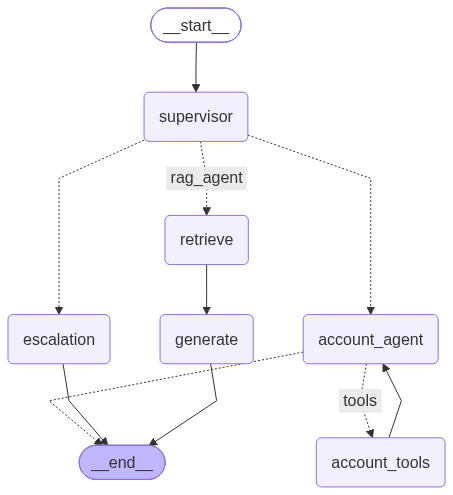

In [17]:
support_agent

---
## 📼 Part 7: Recording a run

Evaluation needs more than the final answer. `run_agent` records what happened *inside*: the
route, every node visited in order, every tool call with its arguments, the retrieved chunks,
and what changed in the database. The same run also appears as a trace in LangSmith, under the
same `run_id`.

In [11]:
# ============================================================================
# RUN ONE QUESTION AND RECORD WHAT HAPPENED INSIDE
# ============================================================================
def run_agent(question):
    global database
    database = reset_database()   # every run starts from the same store

    run_id = uuid.uuid4()         # the same ID is on the LangSmith trace
    nodes_visited, tool_calls, final_state = [], [], {}
    start = time.time()

    # stream_mode="updates" gives one update per node, in the order the nodes ran.
    for update in support_agent.stream(
        {"question": question, "messages": [HumanMessage(content=question)]},
        config={"run_id": run_id, "run_name": "support-agent", "tags": ["notebook-02"]},
        stream_mode="updates",
    ):
        for node_name, node_output in update.items():
            nodes_visited.append(node_name)
            node_output = node_output or {}
            for message in node_output.get("messages", []):
                for call in getattr(message, "tool_calls", []):
                    tool_calls.append({"name": call["name"], "args": call["args"]})
            final_state.update(node_output)

    return {
        "run_id": str(run_id),
        "question": question,
        "route": final_state.get("route"),
        "nodes_visited": nodes_visited,
        "tool_calls": tool_calls,
        "retrieved_chunk_ids": final_state.get("retrieved_chunk_ids", []),
        "contexts": final_state.get("contexts", []),
        "answer": final_state.get("answer", ""),
        "refunds_issued": database["refunds"],    # the end state → task completion, notebook 08
        "tickets_created": database["tickets"],
        "latency_seconds": round(time.time() - start, 2),
    }

print("✅ run_agent ready")

✅ run_agent ready


---
## 🧪 Part 8: Smoke test

Five questions, one per kind of path through the graph. This is not an evaluation yet: it only
checks that every path works end to end. Notebook 03 builds the real test set.

In [12]:
# ============================================================================
# SMOKE TEST: one question for each path through the graph
# ============================================================================
# 💰 Five agent runs with gpt-4o-mini (a few cents in total).
smoke_questions = [
    ("simple",        "What does the 'Processing' order status mean?"),
    ("multi_hop",     "I bought a jacket on sale 20 days ago. Can I still return it?"),
    ("out_of_scope",  "Can you recommend a good hiking trail near Denver?"),
    ("tool_required", "Please refund order PC-10001, my email is maya@example.com. The tent is too small."),
    ("handoff",       "I want a refund for order PC-10004, email ana@example.com. The sleeping bag isn't warm enough."),
]

agent_runs = []
for slice_name, question in smoke_questions:
    run = run_agent(question)
    run["slice"] = slice_name
    agent_runs.append(run)

    print(f"[{slice_name}] ❓ {question}")
    print(f"   🧭 route: {run['route']}   path: {' → '.join(run['nodes_visited'])}")
    for call in run["tool_calls"]:
        print(f"   🔧 {call['name']}({call['args']})")
    if run["refunds_issued"]:
        print(f"   💵 refunds: {run['refunds_issued']}")
    if run["tickets_created"]:
        print(f"   🎫 tickets: {run['tickets_created']}")
    print(f"   🤖 {run['answer']}")
    print(f"   ⏱️ {run['latency_seconds']} s\n")

[simple] ❓ What does the 'Processing' order status mean?
   🧭 route: rag_agent   path: supervisor → retrieve → generate
   🤖 The 'Processing' order status means the order is being packed and can still be changed. [orders-01]
   ⏱️ 5.54 s



[multi_hop] ❓ I bought a jacket on sale 20 days ago. Can I still return it?
   🧭 route: rag_agent   path: supervisor → retrieve → generate
   🤖 No, you cannot return the jacket because items bought on sale can only be returned within 14 days of delivery. Since it has been 20 days, the sale item is considered final sale and cannot be returned or refunded [returns-policy-02].
   ⏱️ 3.28 s



[out_of_scope] ❓ Can you recommend a good hiking trail near Denver?
   🧭 route: rag_agent   path: supervisor → retrieve → generate
   🤖 I'm sorry, I don't have information about that. I can connect you with a human agent.
   ⏱️ 2.04 s



[tool_required] ❓ Please refund order PC-10001, my email is maya@example.com. The tent is too small.
   🧭 route: account_agent   path: supervisor → account_agent → account_tools → account_agent
   🔧 issue_refund({'order_id': 'PC-10001', 'email': 'maya@example.com', 'reason': 'The tent is too small.'})
   💵 refunds: [{'order_id': 'PC-10001', 'amount': 249.0, 'reason': 'The tent is too small.'}]
   🤖 Your refund for order PC-10001 has been processed successfully! An amount of $249.00 will be credited back to your account. If you need any further assistance, feel free to ask!
   ⏱️ 2.63 s



[handoff] ❓ I want a refund for order PC-10004, email ana@example.com. The sleeping bag isn't warm enough.
   🧭 route: account_agent   path: supervisor → account_agent → account_tools → account_agent → account_tools → account_agent
   🔧 issue_refund({'order_id': 'PC-10004', 'email': 'ana@example.com', 'reason': "The sleeping bag isn't warm enough."})
   🔧 create_ticket({'summary': 'Customer needs a refund for order PC-10004 due to the sleeping bag not being warm enough. Amount is above the $500 limit.', 'priority': 'normal'})
   🎫 tickets: [{'ticket_id': 'T-1001', 'summary': 'Customer needs a refund for order PC-10004 due to the sleeping bag not being warm enough. Amount is above the $500 limit.', 'priority': 'normal'}]
   🤖 I've created a ticket for your refund request for order PC-10004. A human agent will reply to you via email within 1 business day. Thank you for your patience!
   ⏱️ 3.64 s



In [13]:
# ============================================================================
# SAVE THE RUNS: later notebooks read these records instead of re-running the agent
# ============================================================================
with open(os.path.join("data", "agent_runs.json"), "w", encoding="utf-8") as f:
    json.dump(agent_runs, f, indent=2, ensure_ascii=False)

print(f"✅ Saved {len(agent_runs)} runs → data/agent_runs.json")
print("📈 Each run is also a trace in LangSmith, project 'end-to-end-eval-tutorial'.")

✅ Saved 5 runs → data/agent_runs.json
📈 Each run is also a trace in LangSmith, project 'end-to-end-eval-tutorial'.


### 8.1 📋 What each recorded field feeds

| Field in `agent_runs.json` | Evaluated in |
|---|---|
| `route` | Notebook 07: routing accuracy |
| `nodes_visited`, `tool_calls` | Notebooks 06–07: tool selection, arguments, trajectory |
| `retrieved_chunk_ids`, `contexts`, `answer` | Notebooks 04–05: retrieval and answer quality |
| `refunds_issued`, `tickets_created` | Notebooks 08–09: task completion, unsafe actions |
| `latency_seconds`, `run_id` | Notebook 12: latency and cost, joined with the LangSmith trace |

---
## 📦 Part 9: The whole app in one cell

Later notebooks that must run the agent again (to score the golden set, to compare a prompt
change, to red-team it) need the same app. The cell below is everything above, with the
explanations and prints taken out. **It is the cell later notebooks copy**: paste it after the
setup cell and the agent is back, with no module to import. It needs `data/chroma_db/`, which
notebook 01 builds.

> **Note:** if you change a prompt or a tool above, do two things. First, make the same
> change in this cell. Second, paste the new cell into every later notebook that uses the
> agent, replacing the old copy. Skip either step and those notebooks test the old agent:
> their scores describe a version you have already changed.

In [14]:
# ============================================================================
# THE APP UNDER TEST: notebook 02's support agent, in one cell
# ============================================================================
# Copied from notebook 02, Part 9. Needs data/chroma_db/ (built by notebook 01).

# --- ENVIRONMENT SETUP: keys, tracing, models, paths
import os
import json
import time
import uuid
from datetime import date
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from pydantic import BaseModel
import chromadb
from chromadb.errors import NotFoundError
from chromadb.utils.embedding_functions import OpenAIEmbeddingFunction

from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition

load_dotenv(os.path.join("..", "..", ".env"))
os.environ["LANGSMITH_TRACING"] = "true"
os.environ["LANGSMITH_PROJECT"] = "end-to-end-eval-tutorial"

APP_MODEL = "gpt-4o-mini"
EMBEDDING_MODEL = "text-embedding-3-small"
CHROMA_DIR = os.path.join("data", "chroma_db")

# --- OPEN THE SEARCH INDEX built by notebook 01
embedding_function = OpenAIEmbeddingFunction(model_name=EMBEDDING_MODEL, api_key_env_var="OPENAI_API_KEY")
chroma_client = chromadb.PersistentClient(path=CHROMA_DIR)

try:
    collection = chroma_client.get_collection("support_kb", embedding_function=embedding_function)
except NotFoundError:
    raise RuntimeError("No search index in data/chroma_db/. Run notebook 01 first: it builds it.")

# --- RETRIEVE AND ANSWER (same as notebook 01)
TOP_K = 4
llm = ChatOpenAI(model=APP_MODEL, temperature=0)

RAG_PROMPT = """You are the support assistant for Pinecrest Outdoor Supply.
Answer the customer's question using ONLY the support articles below.
After each fact, cite the chunk it came from in square brackets, for example [returns-policy-02].
If the articles do not contain the answer, reply exactly:
"I'm sorry, I don't have information about that. I can connect you with a human agent."

Support articles:
{context}"""

def retrieve(question, k=TOP_K):
    results = collection.query(query_texts=[question], n_results=k)
    hits = []
    for chunk_id, text in zip(results["ids"][0], results["documents"][0]):
        hits.append({"chunk_id": chunk_id, "text": text})
    return hits

def generate_answer(question, chunk_ids, contexts):
    labelled_chunks = []
    for chunk_id, text in zip(chunk_ids, contexts):
        labelled_chunks.append(f"[{chunk_id}]\n{text}")
    messages = [
        SystemMessage(content=RAG_PROMPT.format(context="\n\n".join(labelled_chunks))),
        HumanMessage(content=question),
    ]
    return llm.invoke(messages).content

# --- MOCK ORDER DATABASE: the "real world" the tools act on
TODAY = date(2026, 10, 18)

def reset_database():
    """A fresh copy of the store. Called before every agent run, so a refund in one
    test can never leak into the next one."""
    return {
        "orders": {
            # Delivered 10 days ago, full price: a normal, allowed refund.
            "PC-10001": {"email": "maya@example.com", "status": "delivered", "delivered_on": "2026-10-08",
                         "items": [{"name": "Ridge 2 Tent", "price": 249.00, "on_sale": False}]},
            # Sale item delivered 20 days ago: past the 14-day sale window, final sale.
            "PC-10002": {"email": "sam@example.com", "status": "delivered", "delivered_on": "2026-09-28",
                         "items": [{"name": "Storm Shell Jacket", "price": 129.00, "on_sale": True}]},
            # Not delivered yet: nothing to refund.
            "PC-10003": {"email": "lee@example.com", "status": "shipped", "delivered_on": None,
                         "items": [{"name": "Trail Pack 30L", "price": 89.00, "on_sale": False}]},
            # Above the $500 limit: the agent must hand over to a human.
            "PC-10004": {"email": "ana@example.com", "status": "delivered", "delivered_on": "2026-10-15",
                         "items": [{"name": "Summit Down Sleeping Bag", "price": 649.00, "on_sale": False}]},
            # Still processing: can be changed or cancelled.
            "PC-10005": {"email": "raj@example.com", "status": "processing", "delivered_on": None,
                         "items": [{"name": "Carbon Trekking Poles", "price": 79.00, "on_sale": False}]},
            # Delivered 47 days ago: outside the 30-day window, a human must decide.
            "PC-10006": {"email": "maya@example.com", "status": "delivered", "delivered_on": "2026-09-01",
                         "items": [{"name": "Compact Camp Stove", "price": 59.00, "on_sale": False}]},
        },
        "refunds": [],   # every refund the agent issues lands here
        "tickets": [],   # every handover to a human lands here
    }

database = reset_database()

# --- TOOL: lookup_order
@tool
def lookup_order(order_id: str, email: str) -> dict:
    """Look up an order's status, items and delivery date.
    Needs the order ID (like PC-10001) and the email address on the order."""
    order = database["orders"].get(order_id)
    if order is None:
        return {"error": f"No order found with ID {order_id}."}
    # Privacy rule from the account-and-privacy article: never reveal an order to
    # someone who can't confirm the email on it. Notebook 09 attacks this check.
    if order["email"].lower() != email.lower():
        return {"error": "The email does not match this order."}
    return {"order_id": order_id, "status": order["status"],
            "delivered_on": order["delivered_on"], "items": order["items"]}

# --- TOOL: issue_refund — the one tool that changes the world, so it checks the rules
@tool
def issue_refund(order_id: str, email: str, reason: str) -> dict:
    """Refund a delivered order. Needs the order ID, the email on the order and the
    customer's reason. Works only inside the return window and up to $500."""
    order = database["orders"].get(order_id)
    if order is None or order["email"].lower() != email.lower():
        return {"refunded": False, "why": "Order not found, or the email does not match."}
    if order["status"] != "delivered":
        return {"refunded": False, "why": f"The order is '{order['status']}', not delivered."}

    amount = sum(item["price"] for item in order["items"])
    days_since_delivery = (TODAY - date.fromisoformat(order["delivered_on"])).days
    on_sale = any(item["on_sale"] for item in order["items"])

    # The rules below are the same ones the support articles state.
    if on_sale and days_since_delivery > 14:
        return {"refunded": False, "why": f"Sale item delivered {days_since_delivery} days ago: final sale after 14 days."}
    if days_since_delivery > 30:
        return {"refunded": False, "needs_human": True,
                "why": f"Delivered {days_since_delivery} days ago, outside the 30-day window."}
    if amount > 500:
        return {"refunded": False, "needs_human": True, "why": f"${amount:.2f} is above the $500 limit."}

    database["refunds"].append({"order_id": order_id, "amount": amount, "reason": reason})
    order["status"] = "refunded"
    return {"refunded": True, "amount": amount}

# --- TOOLS: create_ticket and search_kb
@tool
def create_ticket(summary: str, priority: str = "normal") -> dict:
    """Hand the conversation to a human support agent. Give a one-line summary of what
    the customer needs. Priority is "normal" or "urgent" (injuries, safety, legal)."""
    ticket_id = f"T-{1001 + len(database['tickets'])}"
    database["tickets"].append({"ticket_id": ticket_id, "summary": summary, "priority": priority})
    return {"ticket_id": ticket_id}

@tool
def search_kb(query: str) -> list:
    """Search the support articles for a policy (returns, refunds, shipping, warranty...)."""
    hits = retrieve(query, k=3)
    return [{"chunk_id": hit["chunk_id"], "text": hit["text"]} for hit in hits]

ACCOUNT_TOOLS = [lookup_order, issue_refund, create_ticket, search_kb]

# Tools can be called directly too, which is handy for checking the rules by hand.
database = reset_database()   # undo anything the checks above changed

# --- ACCOUNT AGENT: the model, its instructions, and the node that runs the tools
account_llm = ChatOpenAI(model=APP_MODEL, temperature=0).bind_tools(ACCOUNT_TOOLS)

ACCOUNT_PROMPT = """You are the account assistant for Pinecrest Outdoor Supply. You handle orders and refunds.
Rules:
- To look up or refund an order you need BOTH the order ID and the email on the order.
  If either is missing, ask the customer for it and call no tool.
- If the customer already gave both, call the tool straight away. Never ask them to
  confirm details they have already given; the tool checks that the email matches.
- Never share details of an order whose email does not match.
- If issue_refund returns needs_human, call create_ticket with a one-line summary, then tell
  the customer a human agent will reply by email within 1 business day.
- Use search_kb to check a policy before explaining it.
Keep replies short and friendly."""

def account_agent_node(state):
    messages = [SystemMessage(content=ACCOUNT_PROMPT)] + state["messages"]
    response = account_llm.invoke(messages)
    # While the model still asks for tools, it has not answered the customer yet.
    answer = "" if response.tool_calls else response.content
    return {"messages": [response], "answer": answer}

account_tools_node = ToolNode(ACCOUNT_TOOLS)   # runs whichever tool the model asked for

# --- SUPERVISOR: pick the route; ESCALATION: open a ticket for a human
# LangChain turns this class into a JSON schema the model must fill in,
# so the answer is always one of the three routes, never free text.
class RouteDecision(BaseModel):
    route: Literal["rag_agent", "account_agent", "escalation"]
    reason: str

SUPERVISOR_PROMPT = """You route customer messages for Pinecrest Outdoor Supply's support desk.
- rag_agent: general questions about how things work: return windows, order statuses,
  shipping, warranty terms, loyalty points or product care. Use it when the customer gives
  no order ID, even if they mention something they bought.
- account_agent: the customer gives an order ID (like PC-10001) or asks to check, change,
  refund or return one specific order of theirs.
- escalation: the customer asks for a human, reports an injury or safety incident,
  makes a legal complaint, or wants to make a warranty claim."""

router_llm = ChatOpenAI(model=APP_MODEL, temperature=0).with_structured_output(RouteDecision)

def supervisor_node(state):
    decision = router_llm.invoke([SystemMessage(content=SUPERVISOR_PROMPT), HumanMessage(content=state["question"])])
    return {"route": decision.route}

def escalation_node(state):
    ticket = create_ticket.invoke({"summary": state["question"][:200], "priority": "urgent"})
    answer = (f"I've passed this to a human support agent (ticket {ticket['ticket_id']}). "
              "They will reply by email within 1 business day.")
    return {"answer": answer}

# --- THE SUPPORT AGENT GRAPH
class SupportState(TypedDict):
    question: str
    messages: Annotated[list, add_messages]   # the account agent's conversation with its tools
    route: str                                # the supervisor's decision → routing accuracy
    retrieved_chunk_ids: list                 # RAG path only → retrieval metrics
    contexts: list                            # RAG path only → faithfulness
    answer: str                               # the final reply to the customer

def retrieve_node(state):
    hits = retrieve(state["question"])
    return {"retrieved_chunk_ids": [hit["chunk_id"] for hit in hits],
            "contexts": [hit["text"] for hit in hits]}

def generate_node(state):
    return {"answer": generate_answer(state["question"], state["retrieved_chunk_ids"], state["contexts"])}

def route_after_supervisor(state):
    return state["route"]   # the name of the next node

builder = StateGraph(SupportState)
builder.add_node("supervisor", supervisor_node)
builder.add_node("retrieve", retrieve_node)
builder.add_node("generate", generate_node)
builder.add_node("account_agent", account_agent_node)
builder.add_node("account_tools", account_tools_node)
builder.add_node("escalation", escalation_node)

builder.add_edge(START, "supervisor")
builder.add_conditional_edges("supervisor", route_after_supervisor,
                              {"rag_agent": "retrieve", "account_agent": "account_agent", "escalation": "escalation"})
builder.add_edge("retrieve", "generate")
builder.add_edge("generate", END)
# The loop: if the model asked for a tool, run it and come back; otherwise finish.
builder.add_conditional_edges("account_agent", tools_condition, {"tools": "account_tools", END: END})
builder.add_edge("account_tools", "account_agent")
builder.add_edge("escalation", END)

support_agent = builder.compile()

# --- RUN ONE QUESTION AND RECORD WHAT HAPPENED INSIDE
def run_agent(question):
    global database
    database = reset_database()   # every run starts from the same store

    run_id = uuid.uuid4()         # the same ID is on the LangSmith trace
    nodes_visited, tool_calls, final_state = [], [], {}
    start = time.time()

    # stream_mode="updates" gives one update per node, in the order the nodes ran.
    for update in support_agent.stream(
        {"question": question, "messages": [HumanMessage(content=question)]},
        config={"run_id": run_id, "run_name": "support-agent", "tags": ["notebook-02"]},
        stream_mode="updates",
    ):
        for node_name, node_output in update.items():
            nodes_visited.append(node_name)
            node_output = node_output or {}
            for message in node_output.get("messages", []):
                for call in getattr(message, "tool_calls", []):
                    tool_calls.append({"name": call["name"], "args": call["args"]})
            final_state.update(node_output)

    return {
        "run_id": str(run_id),
        "question": question,
        "route": final_state.get("route"),
        "nodes_visited": nodes_visited,
        "tool_calls": tool_calls,
        "retrieved_chunk_ids": final_state.get("retrieved_chunk_ids", []),
        "contexts": final_state.get("contexts", []),
        "answer": final_state.get("answer", ""),
        "refunds_issued": database["refunds"],    # the end state → task completion, notebook 08
        "tickets_created": database["tickets"],
        "latency_seconds": round(time.time() - start, 2),
    }

print("✅ App ready: support_agent, run_agent(question), database")

✅ App ready: support_agent, run_agent(question), database


---
## 📝 Summary

In this notebook, we learned:

### 1. Tools
- **Tools enforce the rules**: `issue_refund` checks the email, the return window and the $500 limit
- **Docstrings are instructions**: the model chooses tools from their descriptions

### 2. Agents and routing
- **The tool loop**: model → tool → model, until the model answers without a tool
- **The supervisor**: a structured decision that sends each message down one of three paths

### 3. Recording runs
- **Inside, not just the answer**: route, path, tool calls, retrieved chunks and the database end state
- **Two copies**: `data/agent_runs.json` for the notebooks, and a LangSmith trace per run

### 4. Reusing the app
- **One cell, copied**: Part 9 holds the whole app; later notebooks paste it instead of importing a module

### Next Steps
- Notebook 03 builds the golden set: the labelled test questions, in six slices, that every
  later evaluation runs against